In [2]:
import geopandas as gpd
import h3
import matplotlib as mpl
import matplotlib.pyplot as plt
import polars as pl
import yaml
from shapely import Polygon
from cmcrameri import cm
from detect_home import concat_home_tables

mpl.rcParams["svg.hashsalt"] = "42"

with open("plotting_config.yaml", "r") as fp:
    plotting_config = yaml.safe_load(fp)


with open("../config.budapest.yaml", "r") as fp:
    config = yaml.safe_load(fp)


def add_geometry(x: str):
    """create hex geometry"""
    points = ((i[1], i[0]) for i in h3.cell_to_boundary(x))
    return Polygon(points)


def sum_locations_in_hexagons(data: pl.DataFrame, column: str):
    count = (
        data.group_by(column)
        .agg(pl.col.device_id.count())
        .rename({"device_id": "count"})
    )
    return count

In [3]:
VARIANT = "v2"
RES = 8

In [4]:
census = pl.read_csv(
    f"/mnt/common-hdd/group-dirs/tkom-2026-project/census/h3_{RES}_grouped.csv"
)

In [5]:
hw = pl.read_parquet(
    f"/mnt/common-ssd/group-dirs/tkom-2026-project/pickwell/budapest/homes/{VARIANT}/home_work_h3_{RES}.parquet"
)

<Axes: >

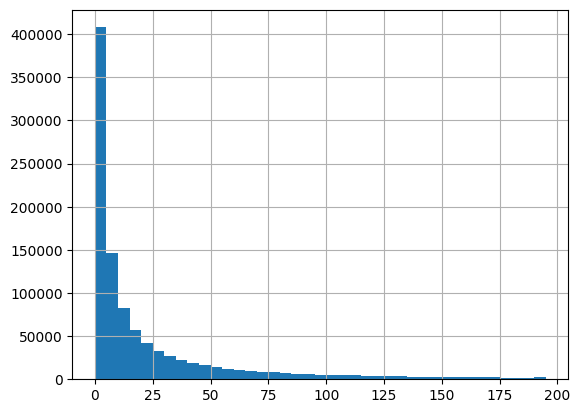

In [6]:
hw.to_pandas()["count_home"].hist(bins=range(0, 200, 5))

<Axes: >

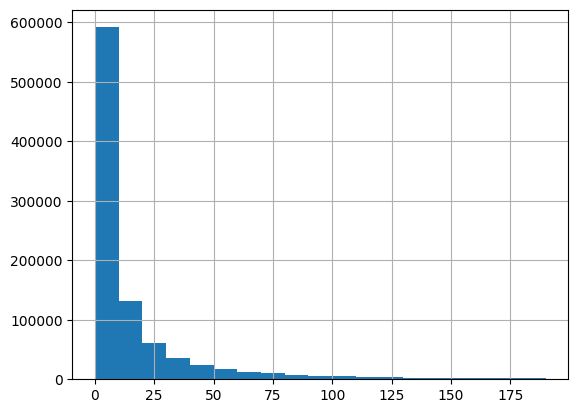

In [7]:
hw.to_pandas()["count_work"].hist(bins=range(0, 200, 10))

In [8]:
home_count = sum_locations_in_hexagons(hw, f"h3_{RES}_home")
work_count = sum_locations_in_hexagons(hw, f"h3_{RES}_work")


In [9]:
home_count["count"].sum()

1137737

In [10]:
h3_geo = gpd.read_file(f"../data/h3/budapest/{RES}.geojson")

In [11]:
h3_homes = h3_geo.merge(
    home_count.rename({f"h3_{RES}_home": "h3"}).to_pandas(), on="h3", how="left"
)  # .fillna(0)


In [12]:
corr = (
    pl.from_pandas(h3_homes[["h3", "count"]])
    .join(census.rename({"h3_id": "h3"}), on="h3")
    .select(pl.corr("count", "pop", method="pearson"))["count"][0]
)
corr

0.929282668676403

In [34]:
corr_log = (
    pl.from_pandas(h3_homes[["h3", "count"]])
    .join(census.rename({"h3_id": "h3"}), on="h3")
    .with_columns(pl.col.count.log(10), pl.col.pop.log(10))
    .select(pl.corr("count", "pop", method="pearson"))["count"][0]
)
corr_log

0.8729628160749021

In [ ]:
# r_log = np.log10(merged["nr_homes_hw"]).corr(np.log10(merged["pop"]))

In [13]:
census[["h3_id", "pop"]].rename({"h3_id": "h3"}).to_pandas()

,h3,pop
0,881e034483fffff,5.0
1,881e034491fffff,19.0
2,881e034493fffff,238.0
3,881e034495fffff,370.0
4,881e034497fffff,930.0
...,...,...
612,881e1cb6d5fffff,188.0
613,881e1cb6d7fffff,1442.0
614,881e1cb6d9fffff,170.0
615,881e1cb6dbfffff,1127.0


In [14]:
from matplotlib.patches import Patch

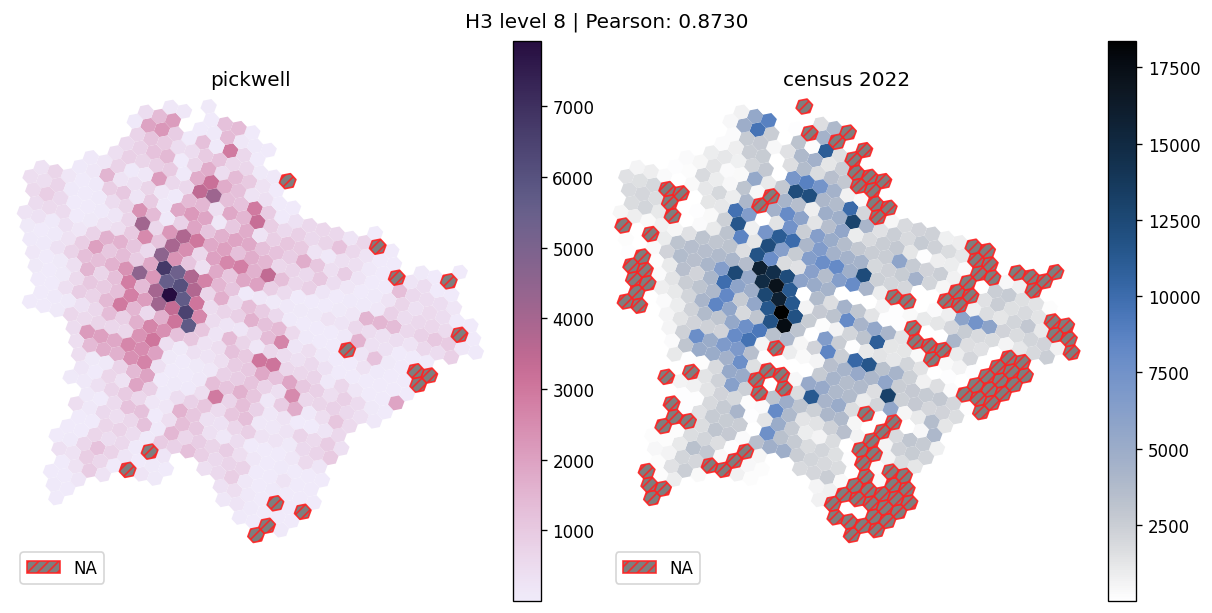

In [ ]:
na_dict = dict(facecolor="#7e7e7e", edgecolor="#ff2222e7", hatch="////")
na_patch = Patch(**na_dict)

fig, axs = plt.subplots(layout="constrained", ncols=2, figsize=(10, 5), dpi=120)
h3_homes.to_crs(23700).plot(
    ax=axs[0],
    column="count",
    cmap=cm.acton_r,
    missing_kwds=na_dict,
    legend=True,
)
axs[0].set_title("pickwell")
axs[1].set_title("census 2022")
fig.suptitle(f"H3 level {RES} | Pearson: {corr:0.04f}")
h3_geo.merge(
    census[["h3_id", "pop"]].rename({"h3_id": "h3"}).to_pandas(), on="h3", how="left"
).to_crs(23700).plot(
    ax=axs[1],
    column="pop",
    cmap=cm.oslo_r,
    missing_kwds=na_dict,
    legend=True,
)

for i in range(2):
    axs[i].margins(0.01)
    axs[i].legend(
        handles=[na_patch], labels=["NA"], loc="lower left", bbox_to_anchor=(0, -0.1)
    )
    _ = axs[i].axis("off")
for i in plotting_config["formats"]:
    suffix = ""
    if VARIANT != "":
        suffix = f"_{VARIANT}"
    fig.savefig(
        f"../output/budapest/figures/detected_population_{RES}{suffix}.{i}",
        pad_inches=0,
        metadata=plotting_config["metadata"][i],
    )


In [19]:
bp = gpd.read_file("../data/osm/budapest/boundary.geojson")

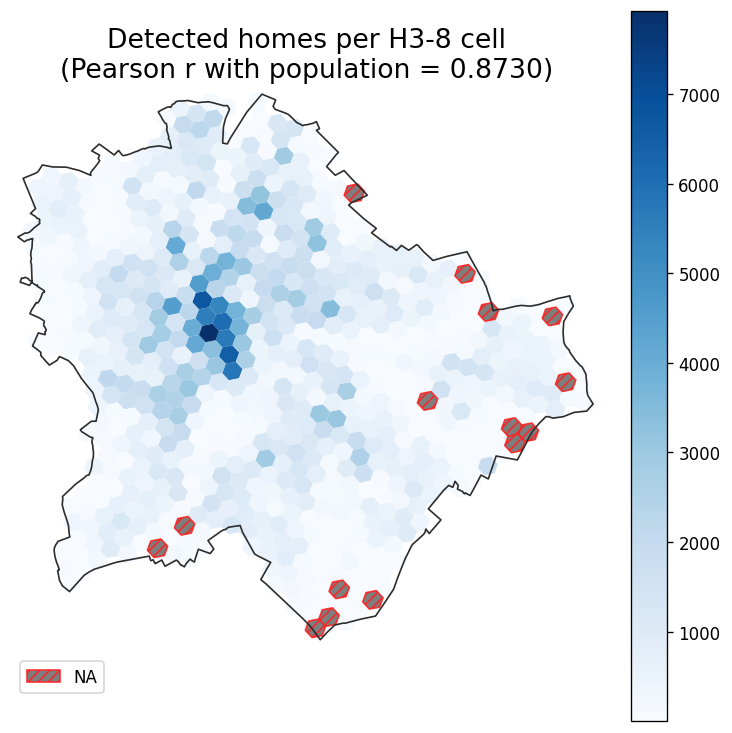

In [36]:
na_dict = dict(facecolor="#7e7e7e", edgecolor="#ff2222e7", hatch="////")
na_patch = Patch(**na_dict)

fig, ax = plt.subplots(layout="constrained", figsize=(6, 6), dpi=120)

ax.set_title(
    f"Detected homes per H3-8 cell\n(Pearson r with population = {corr_log:.4f})",
    fontsize=16,
)
# fig.suptitle(f"H3 level {RES} | Pearson: {corr:0.04f}")
h3_homes.merge(
    census[["h3_id", "pop"]].rename({"h3_id": "h3"}).to_pandas(), on="h3", how="left"
).to_crs(23700).plot(
    ax=ax,
    column="count",
    cmap="Blues",
    missing_kwds=na_dict,
    legend=True,
)
bp.to_crs(23700).plot(ax=ax, ec="#2d2d2d", fc="none")

ax.margins(0.01)
ax.legend(handles=[na_patch], labels=["NA"], loc="lower left", bbox_to_anchor=(0, -0.1))
_ = ax.axis("off")
for i in plotting_config["formats"]:
    suffix = ""
    if VARIANT != "":
        suffix = f"_{VARIANT}"
    fig.savefig(
        f"../output/budapest/figures/fig_homes_h3_map_{RES}{suffix}.{i}",
        pad_inches=0,
        metadata=plotting_config["metadata"][i],
    )
